In [27]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

from compcats.localizer import localizer

import main_analysis as ma
import paths

RESULTS_DIR = 'results'
MODELS_DIR = 'models'

model_localizer = 'grillspector'
model_localizer_dir = paths.GRILLSPECTOR_LOCALIZER_DIR

frois = ['FFA', 'PPA', 'EBA']
tthresholds = [3, 5, 7]
default_threshold = 3

random_model_names = ma.get_model_names('random')

In [25]:
percentage_units_dict = {froi: {tthreshold: [] for tthreshold in tthresholds} for froi in frois}
for model_name in random_model_names:
    model = ma.get_model(model_name)
    for froi in frois:
        layer = ma.get_froi_models_layers(froi, froi)[model_name]
        for tthreshold in tthresholds:
            mask = localizer.get_froi_mask(
                model_localizer_dir,
                model_localizer,
                MODELS_DIR,
                model,
                layer,
                froi,
                tthreshold,
            )
            if 'vit' in model_name and froi == 'EBA':
                # only compute for default threshold for ViTs
                # continue
                print(f'Processing model: {model_name}, layer: {layer}, ROI: {froi}, t-threshold: {tthreshold}, number of units: {mask.sum().item()}')
            percentage_units = mask.sum().item() / mask.numel() * 100
            percentage_units_dict[froi][tthreshold].append(percentage_units)

Initialized alexnetrandom1 with seed = 1
Initialized alexnetrandom2 with seed = 2
Initialized alexnetrandom3 with seed = 3
Initialized alexnetrandom4 with seed = 4
Initialized alexnetrandom5 with seed = 5
Initialized resnet18random1 with seed = 1
Initialized resnet18random2 with seed = 2
Initialized resnet18random3 with seed = 3
Initialized resnet18random4 with seed = 4
Initialized resnet18random5 with seed = 5
Initialized resnet50random1 with seed = 1
Initialized resnet50random2 with seed = 2
Initialized resnet50random3 with seed = 3
Initialized resnet50random4 with seed = 4
Initialized resnet50random5 with seed = 5
Initialized vitb32random1 with seed = 1
Processing model: vitb32random1, layer: encoder.layers.encoder_layer_7.self_attention, ROI: EBA, t-threshold: 3, number of units: 2
Processing model: vitb32random1, layer: encoder.layers.encoder_layer_7.self_attention, ROI: EBA, t-threshold: 5, number of units: 0
Processing model: vitb32random1, layer: encoder.layers.encoder_layer_7.

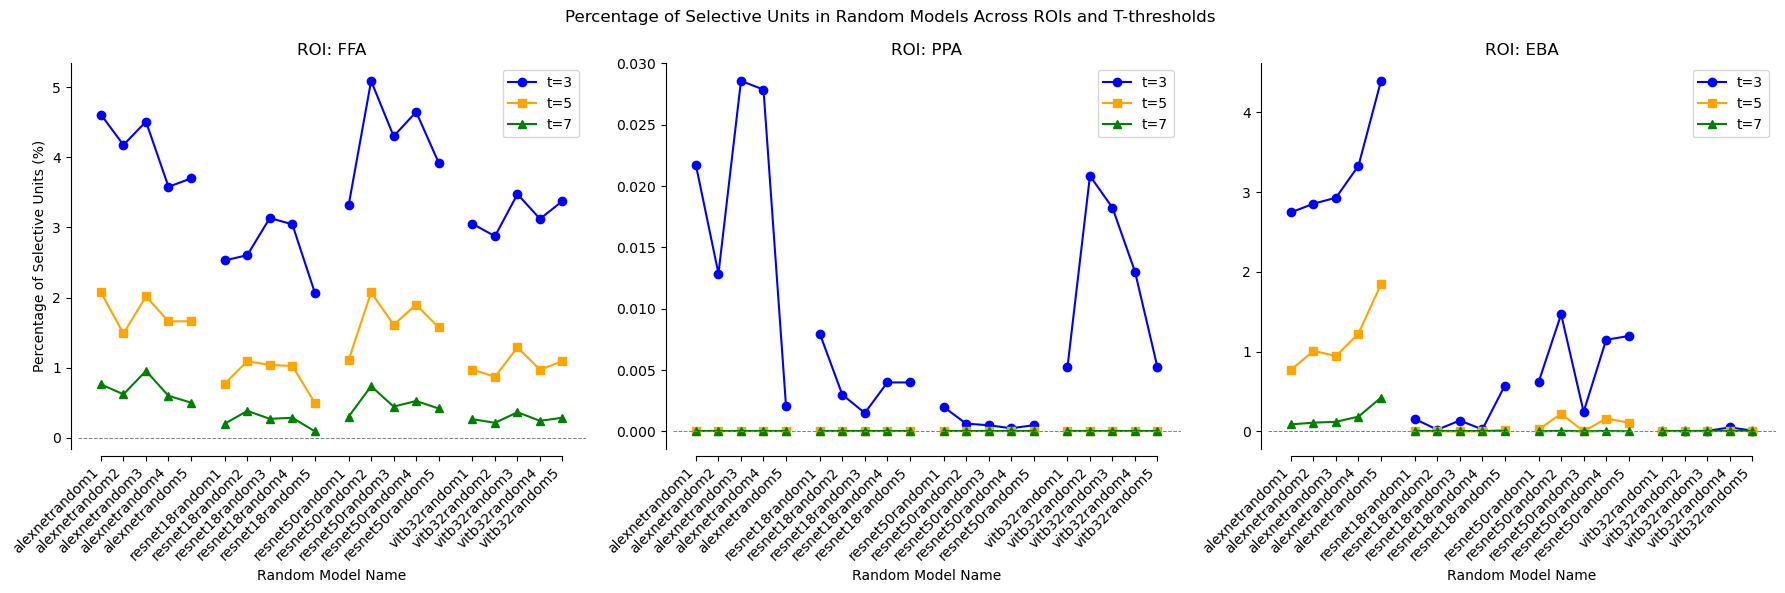

In [ ]:
# Plot 3 subplots, one for each ROI, showing the distribution of percentage of selective units across random models
# The x-axis should be the model_name, y-axis should be the percentage of selective units
# Make 3 lines, one for each t-threshold and mark them with a different marker
markers_dict = {3: 'o', 5: 's', 7: '^'}
colors_dict = {3: 'blue', 5: 'orange', 7: 'green'}

fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Define architecture boundaries and add gaps
arch_boundaries = [0, 5, 10, 15, 20]  # alexnet, resnet18, resnet50, vitb32
gap_size = 0.5

for i, froi in enumerate(frois):
    ax = axs[i]
    
    # Create x_positions with gaps between architectures
    x_positions_with_gaps = []
    current_pos = 0
    for j in range(len(random_model_names)):
        x_positions_with_gaps.append(current_pos)
        current_pos += 1
        # Add gap after every 5th model (architecture boundary)
        if (j + 1) % 5 == 0 and j < len(random_model_names) - 1:
            current_pos += gap_size
    
    for tthreshold in tthresholds:
        percentages = percentage_units_dict[froi][tthreshold]
        # Plot lines for different model families with gaps
        ax.plot(x_positions_with_gaps[:5], percentages[:5], marker=markers_dict[tthreshold], color=colors_dict[tthreshold], label=f't={tthreshold}')
        ax.plot(x_positions_with_gaps[5:10], percentages[5:10], marker=markers_dict[tthreshold], color=colors_dict[tthreshold])
        ax.plot(x_positions_with_gaps[10:15], percentages[10:15], marker=markers_dict[tthreshold], color=colors_dict[tthreshold])
        ax.plot(x_positions_with_gaps[15:20], percentages[15:20], marker=markers_dict[tthreshold], color=colors_dict[tthreshold])
    
    ax.set_title(f'ROI: {froi}')
    ax.set_xlabel('Random Model Name')
    if i == 0:
        ax.set_ylabel('Percentage of Selective Units (%)')
    ax.legend()
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_bounds(x_positions_with_gaps[0], x_positions_with_gaps[-1])
    ax.set_xticks(x_positions_with_gaps)
    ax.set_xticklabels(random_model_names, rotation=45, ha='right')

plt.suptitle('Percentage of Selective Units in Random Models Across ROIs and T-thresholds')
plt.tight_layout()
plt.show()

In [37]:
localization_validation_csv_path = f'{RESULTS_DIR}/localization_validation_grillspector_val_prince2024_randommodels_layerfortthreshold3.csv'
localization_validation_csv = pd.read_csv(localization_validation_csv_path)

# Check if layers are consistent, collapse across (model_name, froi, tthreshold) and print the model_name and froi if there are multiple layers
for model_name in random_model_names:
    for froi in frois:
        for tthreshold in tthresholds:
            layers = localization_validation_csv[
                (localization_validation_csv['model_name'] == model_name) &
                (localization_validation_csv['model_froi'] == froi) &
                (localization_validation_csv['model_froi_tthreshold'] == tthreshold)
            ]['model_layer'].unique()
            if len(layers) > 1:
                print(f'Model: {model_name}, ROI: {froi}, T-threshold: {tthreshold}, Layers: {layers}')

In [53]:
n_models_generalized = {froi: {tthreshold: 0 for tthreshold in tthresholds} for froi in frois}
for _, row in localization_validation_csv.iterrows():
    froi = row['model_froi']
    tthreshold = row['model_froi_tthreshold']
    layer = row['model_layer']
    val_u_pvals = row['validation_u_pvalues']
    if 'nan' in val_u_pvals:
        val_u_pvals = val_u_pvals.replace('nan', 'None')
    val_u_pvals = ast.literal_eval(val_u_pvals)
    if any(pval is None for pval in val_u_pvals):
        continue
    # Check if all p-values are less than 0.05
    if all(pval < 0.05 for pval in val_u_pvals):
        n_models_generalized[froi][tthreshold] += 1

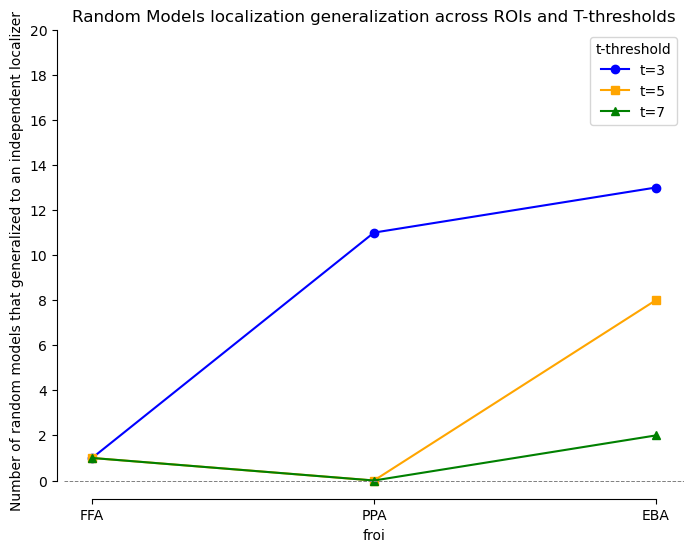

In [69]:
# Make a plot with froi on x-axis, number of models that generalized on y-axis, and a line for each t-threshold
fig, ax = plt.subplots(figsize=(8, 6))
x = frois
for tthreshold in tthresholds:
    y = [n_models_generalized[froi][tthreshold] for froi in frois]
    ax.plot(x, y, marker=markers_dict[tthreshold], color=colors_dict[tthreshold], label=f't={tthreshold}')
ax.set_xlabel('froi')
ax.set_ylabel('Number of random models that generalized to an independent localizer')
ax.legend(title='t-threshold')
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.7)
ax.set_ylim(-0.5, len(random_model_names))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['left'].set_position(('outward', 5))
ax.spines['left'].set_bounds(0, len(random_model_names))
ax.spines['bottom'].set_bounds(0, len(frois)-1)
# set y-ticks every 2 units
ax.set_yticks(range(0, len(random_model_names)+1, 2))
ax.set_title('Random Models localization generalization across ROIs and T-thresholds')
plt.show()